# `tssf` tutorial: scale-rich networks and their interpolation to line lattices

This notebook walks through the `tssf` package:

1. the **scale-rich (SR)** process of Both *et al.* ([arXiv:2511.18108](https://arxiv.org/abs/2511.18108)) and its statistics;
2. **template-snapped sequential fragmentation (TSSF)**: target lattices and the two disorder amplitudes $(\varepsilon_\theta, \varepsilon_x)$;
3. why the ligament-as-node representation is **history dependent**, and the history-free **strut** representation;
4. **order parameters**, junction merging and coordination against the analytical predictions;
5. **rigidity** (Maxwell counting) and the **frame-model stiffness**, including the spanning-strut floor;
6. the **template-free** variant and the thickness schedule.

All networks live in the unit square and are zero-thickness skeletons; thickness enters through the resolution $\tau$, the sliver cutoff $w_{\min}$ and the beam width. The notebook runs in about two minutes.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tssf

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
print("tssf", tssf.__version__)

tssf 0.1.0


## 1. The SR process

At each step a point $\mathbf{x}$ is drawn uniformly in the void and an angle $\theta$ uniformly in $[0,\pi)$; a straight ligament grows through $\mathbf{x}$ in both directions until it touches an existing ligament or the boundary. Every junction is a T-junction and the void stays a set of convex cells. `Network(seed=...)` with no lattice is the SR process; `run(T=...)` inserts `T` ligaments.

In SR the thickness decays with insertion order, $\lambda_t=\lambda_0 t^{-\alpha}$; `Network.thickness` returns it and `plot_network(..., alpha=...)` draws it.

Network(target=SR, eps_theta=1.0, eps_x=1.0, w_min=0, ligaments=3000)


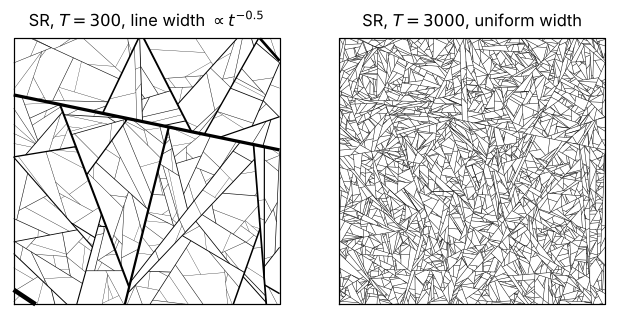

thickness of the first and last ligament: 0.02 0.00036514837167011074


In [ ]:
sr = tssf.Network(seed=0).run(T=3000)
print(sr)

fig, axs = plt.subplots(1, 2, figsize=(7, 3.5))
tssf.plot_network(tssf.Network(seed=0).run(T=300), axs[0], linewidth=3, alpha=0.5)
axs[0].set_title(r"SR, $T=300$, line width $\propto t^{-0.5}$")
tssf.plot_network(sr, axs[1], linewidth=0.3)
axs[1].set_title(r"SR, $T=3000$, uniform width")
plt.show()

lam = sr.thickness(lambda0=0.02, alpha=0.5)
print("thickness of the first and last ligament:", lam[0], lam[-1])

**Length decay.** $t$ cuts make $t+1$ cells, so the chord of the cell being split decays as $\langle \ell_t\rangle \simeq c\, t^{-1/2}$. The prefactor $c$ is of order one: $\ell_0 = (4/\pi)[\ln(1+\sqrt2)+(1-\sqrt2)/3] \approx 0.946$ is the mean chord of the empty square ($t=1$), and later $c\approx1.1$–$1.2$. The ligament-as-node graph of Both *et al.* has $P(\ell)\propto \ell^{-3}$ and $P(k)\propto k^{-3}$.

l0 = 0.94640 (t = 1);  prefactor c = mean of l_t sqrt(t) for t > 100: 1.177
tail exponents: length 2.97, degree 2.96


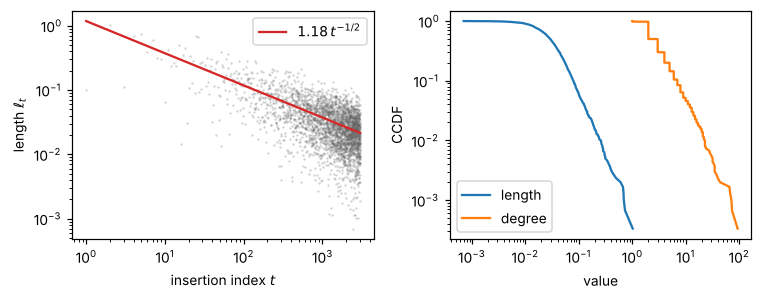

In [ ]:
lengths, degrees = tssf.ligament_graph(sr)
t = np.arange(1, sr.n_ligaments + 1)
l0 = 4 / np.pi * (np.log(1 + np.sqrt(2)) + (1 - np.sqrt(2)) / 3)
c = np.mean(lengths[100:] * np.sqrt(t[100:]))
print(f"l0 = {l0:.5f} (t = 1);  prefactor c = mean of l_t sqrt(t) for t > 100: {c:.3f}")
print(f"tail exponents: length {tssf.tail_exponent(lengths, 0.05):.2f}, degree {tssf.tail_exponent(degrees - 0.5, 9.5):.2f}")

fig, axs = plt.subplots(1, 2, figsize=(7, 2.8))
axs[0].loglog(t, lengths, ".", ms=1, alpha=0.3, color="0.4")
axs[0].loglog(t, c / np.sqrt(t), "C3", label=rf"${c:.2f}\,t^{{-1/2}}$")
axs[0].set(xlabel="insertion index $t$", ylabel=r"length $\ell_t$"); axs[0].legend()
for x, lab in [(lengths, "length"), (degrees, "degree")]:
    xs = np.sort(x); axs[1].loglog(xs, 1 - np.arange(len(xs)) / len(xs), label=lab)
axs[1].set(xlabel="value", ylabel="CCDF"); axs[1].legend()
plt.tight_layout(); plt.show()

## 2. Target lattices and template snapping

A `LineLattice` is a set of $m$ families of parallel lines. The square lattice has $m=2$; the triangular and kagome lattices have $m=3$. Kagome is the triangular arrangement with one family shifted by half a spacing. Each proposal $(\mathbf{x},\theta)$ is mapped by

$$\theta'=\varphi_f+\varepsilon_\theta(\theta-\varphi_f),\qquad \mathbf{x}'=\mathbf{x}-(1-\varepsilon_x)\,d\,\mathbf{n}_f ,$$

where $f$ is the nearest director family and $d$ the offset of $\mathbf{x}$ from the nearest line of that family. $\varepsilon_\theta=\varepsilon_x=1$ is SR. With $\varepsilon_\theta=\varepsilon_x=0$, run to jamming (`run()` without `T`), the network is exactly the lattice, whatever the insertion order. The sliver cutoff `w_min` rejects splits that leave a daughter cell thinner than `w_min`. `lattice.default_w_min` (half the smallest face width) is the value used in the report.

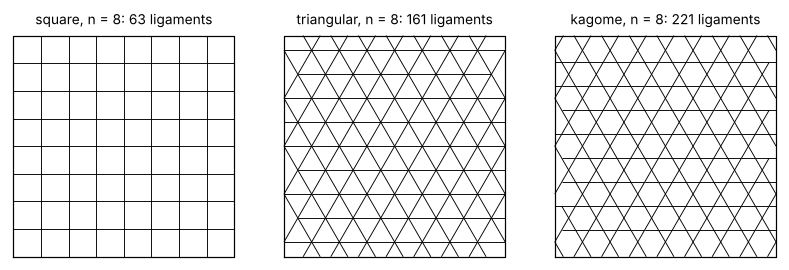

kagome faces: hexagon/triangle area ratio = 6.00 (expected 6)


In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(9, 3))
for ax, name in zip(axs, ["square", "triangular", "kagome"]):
    lat = tssf.make_lattice(name, 8)
    net = tssf.Network(lat, eps_theta=0, eps_x=0, w_min=lat.default_w_min, seed=1).run()
    tssf.plot_network(net, ax, linewidth=0.6)
    ax.set_title(f"{name}, n = 8: {net.n_ligaments} ligaments", fontsize=9)
plt.show()

# kagome check: hexagons and triangles of edge a/2 have area ratio 6
kag = tssf.Network(tssf.kagome_lattice(8), 0, 0, w_min=tssf.kagome_lattice(8).default_w_min, seed=1).run()
vals, counts = np.unique(np.round(kag.cell_areas / kag.cell_areas.max(), 4), return_counts=True)
hexagon, triangle = sorted(vals[np.argsort(counts)[-2:]], reverse=True)   # the two most common face areas
print(f"kagome faces: hexagon/triangle area ratio = {hexagon / triangle:.2f} (expected 6)")

### The two-parameter path

Orientational order comes first ($\varepsilon_\theta=0$: the *aligned* network). Positional order follows as $\varepsilon_x\to0$. Below $\varepsilon_x h < w_{\min}$ (here $\varepsilon_x<1/2$ for the square lattice; $1/3$ triangular, $1/6$ kagome) the network is *registered*: one staggered strut per lattice line.

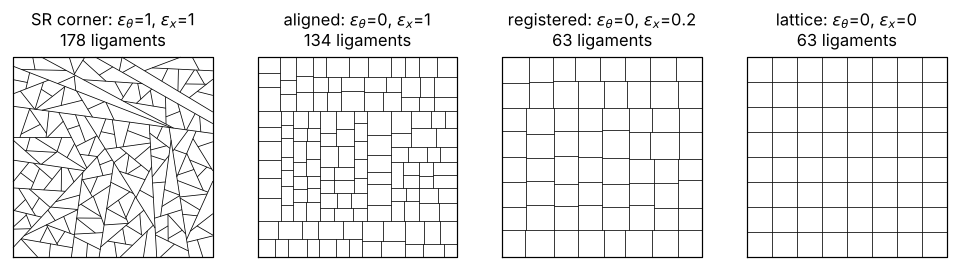

In [ ]:
lat = tssf.square_lattice(8)
corners = [(1, 1, "SR corner"), (0, 1, "aligned"), (0, 0.2, "registered"), (0, 0, "lattice")]
fig, axs = plt.subplots(1, 4, figsize=(11, 3))
for ax, (eth, ex, label) in zip(axs, corners):
    net = tssf.Network(lat, eps_theta=eth, eps_x=ex, w_min=lat.default_w_min, seed=10).run()
    tssf.plot_network(net, ax, linewidth=0.5)
    ax.set_title(f"{label}: $\\varepsilon_\\theta$={eth}, $\\varepsilon_x$={ex}\n{net.n_ligaments} ligaments")
plt.show()

## 3. History dependence and the strut representation

In the ligament-as-node graph a node is one insertion event. A lattice line built from many insertions therefore splits into many "ligaments", and a perfect lattice built in random order looks scale-rich. `struts(net, tau)` gives a history-free representation instead. Junctions closer than $\tau$ form one solid node, and ligament ends meeting anti-parallel at a node form one continuous strut. Physically, $\tau$ is of the order of the strut width. For the $n\times n$ square lattice the strut graph is $K_{n-1,n-1}$.

history: 575 ligaments, length CV 1.28, degree range 1-46
struts : 46 struts, lengths [1.], degrees [23]


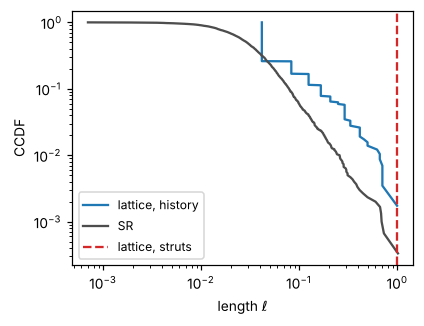

In [ ]:
lat = tssf.square_lattice(24)
grid = tssf.Network(lat, 0, 0, w_min=lat.default_w_min, seed=0).run()
hist_len, hist_deg = tssf.ligament_graph(grid)
s = tssf.struts(grid, tau=1e-6)
print(f"history: {grid.n_ligaments} ligaments, length CV {tssf.cv(hist_len):.2f}, degree range {hist_deg.min()}-{hist_deg.max()}")
print(f"struts : {len(s.lengths)} struts, lengths {np.unique(s.lengths.round(6))}, degrees {np.unique(s.degrees)}")

fig, ax = plt.subplots(figsize=(4, 3))
xs = np.sort(hist_len); ax.loglog(xs, 1 - np.arange(len(xs)) / len(xs), label="lattice, history")
xs = np.sort(lengths); ax.loglog(xs, 1 - np.arange(len(xs)) / len(xs), color="0.3", label="SR")
ax.axvline(1, color="C3", ls="--", label="lattice, struts")
ax.set(xlabel=r"length $\ell$", ylabel="CCDF"); ax.legend(fontsize=8); plt.show()

## 4. Order parameters, merging and coordination

**P1.** Since $\theta$ and $d$ are uniform, the length-weighted orientational order $\Psi_{2m}$ and the translational order $\Phi$ obey

$$\Psi_{2m}(\varepsilon_\theta)=\frac{\sin\pi\varepsilon_\theta}{\pi\varepsilon_\theta},\qquad \Phi(\varepsilon_x)=\frac{\sin\pi\varepsilon_x}{\pi\varepsilon_x}\ \ \text{(registered regime)} .$$

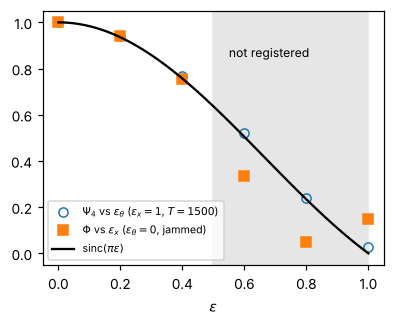

In [ ]:
lat = tssf.square_lattice(8)
eps = np.linspace(0, 1, 6)
psi = [tssf.orientational_order(tssf.Network(lat, e, 1.0, seed=2).run(T=1500), lat.m) for e in eps]
phi = [tssf.translational_order(tssf.Network(lat, 0.0, e, w_min=lat.default_w_min, seed=2).run(), lat) for e in eps]
e = np.linspace(0, 1, 100)
plt.figure(figsize=(4, 3))
plt.plot(eps, psi, "o", mfc="none", label=r"$\Psi_4$ vs $\varepsilon_\theta$ ($\varepsilon_x=1$, $T=1500$)")
plt.plot(eps, phi, "s", label=r"$\Phi$ vs $\varepsilon_x$ ($\varepsilon_\theta=0$, jammed)")
plt.plot(e, np.sinc(e), "k-", label=r"sinc$(\pi\varepsilon)$")
plt.axvspan(0.5, 1, color="0.9", zorder=-1); plt.text(0.55, 0.85, "not registered", fontsize=8)
plt.xlabel(r"$\varepsilon$"); plt.legend(fontsize=7); plt.show()

**P2–P3.** In the registered regime a lattice crossing consists of a through-strut and two stubs with i.i.d. offsets. The stubs merge into one strut when their stagger $s=\varepsilon_x|d_1-d_2|/\sin\gamma$ falls below $\tau$, so the merge fraction is $f=F(u)=1-(1-u)^2$ with $u=\tau\sin\gamma/(\varepsilon_x h)$. Pairwise T$\to$X merging then gives the mean interior coordination $z=2(3-f)/(2-f)$, which stays below the Maxwell value $4$ until $f=1$.

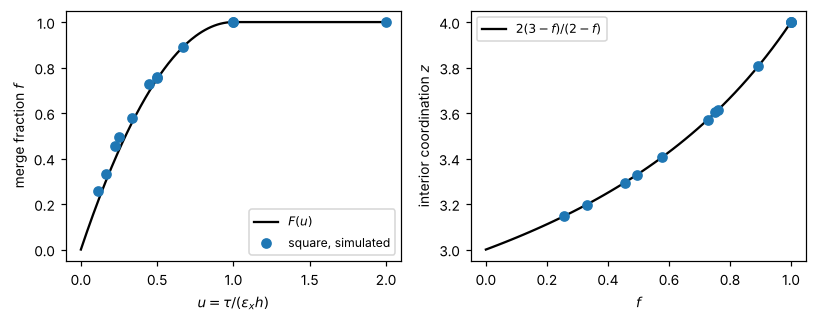

In [ ]:
lat = tssf.square_lattice(12)
rows = []
for ex in [0.1, 0.2, 0.3, 0.45]:
    net = tssf.Network(lat, 0.0, ex, w_min=lat.default_w_min, seed=1).run()
    for t in [0.05, 0.1, 0.2]:
        s = tssf.struts(net, t * lat.h)
        rows.append((t / ex, tssf.merge_fraction(net, s), tssf.mean_coordination(s.nodes, s.edges)[0]))
u, f, z = np.array(rows).T
fig, axs = plt.subplots(1, 2, figsize=(7.5, 3))
uu = np.linspace(0, u.max(), 200)
axs[0].plot(uu, np.where(uu < 1, 1 - (1 - np.minimum(uu, 1)) ** 2, 1), "k-", label="$F(u)$")
axs[0].plot(u, f, "o", label="square, simulated"); axs[0].set(xlabel=r"$u=\tau/(\varepsilon_x h)$", ylabel="merge fraction $f$")
ff = np.linspace(0, 1, 50)
axs[1].plot(ff, 2 * (3 - ff) / (2 - ff), "k-", label="$2(3-f)/(2-f)$")
axs[1].plot(f, z, "o"); axs[1].set(xlabel="$f$", ylabel="interior coordination $z$")
for ax in axs: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Rigidity and stiffness

**Maxwell counting.** `rigidity(nodes, edges)` returns the floppy modes and states of self-stress of the pin-jointed junction graph. On the square path $z\le4$ throughout, so the network stays floppy. On the triangular path $z$ climbs to $6$ and crosses the isostatic point.

In [ ]:
lat = tssf.triangular_lattice(8)
print(" eps_x   z     floppy/node  self-stress/node   (tau = 0.1 h)")
for ex in [0.45, 0.3, 0.2, 0.1, 0.0]:
    net = tssf.Network(lat, 0.0, ex, w_min=lat.default_w_min, seed=0).run()
    s = tssf.struts(net, 0.1 * lat.h)
    z = tssf.mean_coordination(s.nodes, s.edges)[0]
    floppy, stress = tssf.rigidity(s.nodes, s.edges)
    print(f" {ex:4.2f}  {z:4.2f}     {floppy / len(s.nodes):5.3f}          {stress / len(s.nodes):5.3f}")

 eps_x   z     floppy/node  self-stress/node   (tau = 0.1 h)


 0.45  3.51     0.287          0.000


 0.30  3.80     0.178          0.000


 0.20  4.20     0.041          0.006


 0.10  5.71     0.017          0.440


 0.00  5.96     0.018          0.465


**Frame model.** `uniaxial_modulus(net, lam, axis)` dresses the skeleton with Timoshenko beams of width $\lambda$ and compresses the sample between bonded platens; it returns $E/E_s$ and $\bar\rho=\lambda\sum\ell$. Straight struts that join the two loaded faces carry load axially. They set a floor $E/(E_s\bar\rho)\ge\sum\cos^3\psi/L_{\rm tot}$, returned by `spanning_floor`. After subtracting it, the stiffness along the registered path depends only on $\lambda/(\varepsilon_x h)$.

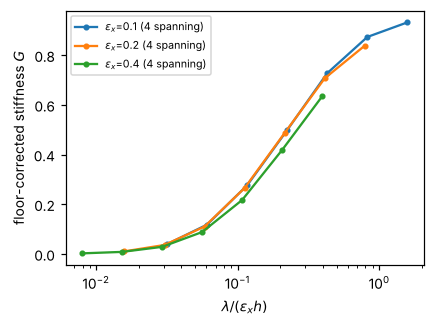

SR, T=150: E/(E_s rho) = 0.0735, predicted floor = 0.0733


In [ ]:
lat = tssf.square_lattice(10)
ref = 0.5                                   # exact square lattice along an axis: E/(E_s rho) = 1/2
lams = np.logspace(-2.5, -0.8, 7)
plt.figure(figsize=(4.2, 3))
for ex in [0.1, 0.2, 0.4]:
    net = tssf.Network(lat, 0.0, ex, w_min=lat.default_w_min, seed=1).run()
    floor, n_span = tssf.spanning_floor(net, "y")
    spec = np.array([np.divide(*tssf.uniaxial_modulus(net, l * lat.h, axis="y")) for l in lams])
    plt.semilogx(lams / ex, (spec - floor) / (ref - floor), "o-", ms=3, label=f"$\\varepsilon_x$={ex} ({n_span} spanning)")
plt.xlabel(r"$\lambda/(\varepsilon_x h)$"); plt.ylabel("floor-corrected stiffness $G$"); plt.legend(fontsize=7); plt.show()

# SR: the small-lambda stiffness is exactly the floor of the root chord (when it spans the loaded faces)
sr150 = tssf.Network(seed=15000).run(T=150)
E, rho = tssf.uniaxial_modulus(sr150, 0.0003, axis="y")
print(f"SR, T=150: E/(E_s rho) = {E / rho:.4f}, predicted floor = {tssf.spanning_floor(sr150, 'y')[0]:.4f}")

## 6. Template-free variant and data export

`ErreraNetwork(q, s, kappa)` replaces the target lattice by local division rules: a cell is chosen with probability $\propto A^q$, the point is $\mathbf{c}+s(\mathbf{u}-\mathbf{c})$, and the orientation follows a stochastic Errera rule $p(\theta)\propto e^{-\kappa\ell(\theta)/\sqrt{A}}$. The choice $(1,1,0)$ is SR. The choice $(\infty,0,\infty)$ (largest cell, centroid, shortest chord) builds the exact $2^k\times2^k$ grid at $t=4^k-1$.

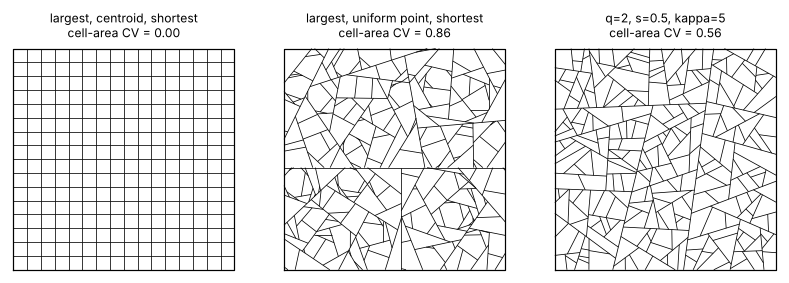

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(9, 3))
for ax, (q, s_, kap, title) in zip(axs, [(np.inf, 0, np.inf, "largest, centroid, shortest"),
                                         (np.inf, 1, np.inf, "largest, uniform point, shortest"),
                                         (2, 0.5, 5, "q=2, s=0.5, kappa=5")]):
    net = tssf.ErreraNetwork(q=q, s=s_, kappa=kap, seed=1).run(T=255)
    tssf.plot_network(net, ax, linewidth=0.5)
    ax.set_title(f"{title}\ncell-area CV = {tssf.cv(net.cell_areas):.2f}", fontsize=8)
plt.show()

In [ ]:
# Ligament data are plain NumPy arrays (insertion order), easy to export for FE meshing or analysis.
net = tssf.Network(tssf.square_lattice(8), 0.0, 0.2, w_min=0.0625, seed=1).run()
lig = net.ligaments
print(lig._fields)
np.savez("network.npz", start=lig.start, end=lig.end, host_start=lig.host_start, host_end=lig.host_end,
         thickness=net.thickness(lambda0=0.01, alpha=0.0))
print("saved", net.n_ligaments, "ligaments to network.npz")

('start', 'end', 'host_start', 'host_end', 'theta', 'family', 'offset', 'length')
saved 63 ligaments to network.npz


### Where to go next

- `experiments/run_experiments.py` regenerates all data of the report, and `experiments/make_figures.py` its REVTeX figures.
- Caveats: zero-thickness skeleton, linear slender-beam mechanics, small samples. Keep $\tau$ well below the smallest lattice edge, because single-linkage clustering chains.